In [ ]:
!pip install pandas numpy scikit-learn matplotlib openpyxl

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GroupKFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")

RANDOM_SEED = 42

# Loading Dataset

In [ ]:
file_path = "PAQFE_UTS_Dataset_Corrected (1).xlsx"

df = pd.read_excel(
    file_path,
    sheet_name="B_Model_Ready"
)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (49, 25)


,Observation_ID,Al,Co,Cr,Fe,Ni,Al_norm,Co_norm,Cr_norm,Fe_norm,...,delta,Omega,dchi,Mean_Tm,OSHE,NVC,Temperature_C,Strain_rate,log10_Strain_rate,UTS_MPa
0,OBS_001,0.000,0.250,0.250,0.250,0.250,0.000000,0.250000,0.250000,0.250000,...,1.103880,5.752837,0.096695,1871.750000,NaN,NaN,900,0.001,-3.0,130.0
1,OBS_002,0.048,0.238,0.238,0.238,0.238,0.048000,0.238000,0.238000,0.238000,...,3.076890,3.685665,0.104482,1826.714000,NaN,NaN,900,0.001,-3.0,148.0
2,OBS_003,0.111,0.222,0.222,0.222,0.222,0.111111,0.222222,0.222222,0.222222,...,4.328494,2.557021,0.112546,1767.500000,NaN,NaN,900,0.001,-3.0,172.0
3,OBS_004,0.130,0.217,0.217,0.217,0.217,0.130261,0.217435,0.217435,0.217435,...,4.604955,2.349226,0.114579,1749.533066,NaN,NaN,900,0.001,-3.0,188.0
4,OBS_005,0.200,0.200,0.200,0.200,0.200,0.200000,0.200000,0.200000,0.200000,...,5.376204,1.829117,0.120565,1684.100000,NaN,NaN,900,0.001,-3.0,215.0


# Features and Target Attributes

In [ ]:
FEATURES = [
    "xAl",
    "VEC",
    "dHmix",
    "dSmix",
    "delta",
    "Omega",
    "dchi",
    "Mean_Tm",
    "Temperature_C",
    "log10_Strain_rate"
]

TARGET = "UTS_MPa"

X = df[FEATURES].copy()
y = df[TARGET].copy()

print("Features:")
for feature in FEATURES:
    print(" -", feature)

print("\nTarget:", TARGET)

Features:
 - xAl
 - VEC
 - dHmix
 - dSmix
 - delta
 - Omega
 - dchi
 - Mean_Tm
 - Temperature_C
 - log10_Strain_rate

Target: UTS_MPa


# Dataset characterization

In [ ]:
print("========== DATASET CHARACTERIZATION ==========")

print("Total observations:", len(df))
print("Valid UTS observations:", df[TARGET].notna().sum())

print("\nUTS Statistics:")
print(df[TARGET].describe())

========== DATASET CHARACTERIZATION ==========
Total observations: 49
Valid UTS observations: 49

UTS Statistics:
count      49.000000
mean      508.822449
std       399.135074
min        25.000000
25%       198.000000
50%       290.000000
75%       805.000000
max      1562.000000
Name: UTS_MPa, dtype: float64


# Checking Null Values

In [ ]:
print("Missing values in selected features:")
display(X.isnull().sum())

print("\nMissing values in target:")
print(y.isnull().sum())

Missing values in selected features:


,0
xAl,0
VEC,0
dHmix,0
dSmix,0
delta,0
Omega,0
dchi,0
Mean_Tm,0
Temperature_C,0
log10_Strain_rate,0



Missing values in target:
0


# Correct composition grouping

In [ ]:
composition_cols = [
    "Al_norm",
    "Co_norm",
    "Cr_norm",
    "Fe_norm",
    "Ni_norm"
]

df["Composition_Group"] = (
    df[composition_cols]
    .round(3)
    .astype(str)
    .agg("_".join, axis=1)
)

In [ ]:
print(
    "Number of unique alloy compositions:",
    df["Composition_Group"].nunique()
)

print("\nObservations per composition:")
print(
    df["Composition_Group"]
    .value_counts()
    .sort_values(ascending=False)
)

Number of unique alloy compositions: 14

Observations per composition:
Composition_Group
0.164_0.164_0.164_0.164_0.344    11
0.059_0.235_0.235_0.235_0.235     8
0.07_0.233_0.233_0.233_0.233      8
0.2_0.2_0.2_0.2_0.2               6
0.13_0.217_0.217_0.217_0.217      5
0.024_0.244_0.244_0.244_0.244     3
0.231_0.192_0.192_0.192_0.192     1
0.111_0.222_0.222_0.222_0.222     1
0.0_0.25_0.25_0.25_0.25           1
0.048_0.238_0.238_0.238_0.238     1
0.167_0.208_0.208_0.208_0.208     1
0.091_0.227_0.227_0.227_0.227     1
0.333_0.167_0.167_0.167_0.167     1
0.273_0.182_0.182_0.182_0.182     1
Name: count, dtype: int64


# Identify repeated compositions

The dataset contains repeated measurements for several alloy compositions, with substantial within-composition variation in UTS.

In [ ]:
composition_summary = (
    df.groupby("Composition_Group")
      .agg(
          Number_of_Observations=("Observation_ID", "count"),
          Mean_UTS=("UTS_MPa", "mean"),
          SD_UTS=("UTS_MPa", "std"),
          Min_UTS=("UTS_MPa", "min"),
          Max_UTS=("UTS_MPa", "max")
      )
      .sort_values("Number_of_Observations", ascending=False)
)

display(composition_summary)

,Number_of_Observations,Mean_UTS,SD_UTS,Min_UTS,Max_UTS
Composition_Group,,,,,
0.164_0.164_0.164_0.164_0.344,11,529.090909,580.473678,25.0,1562.0
0.07_0.233_0.233_0.233_0.233,8,649.037500,356.654951,35.0,1060.0
0.059_0.235_0.235_0.235_0.235,8,679.125000,184.901084,271.0,807.0
0.2_0.2_0.2_0.2_0.2,6,280.000000,91.426473,204.0,400.0
0.13_0.217_0.217_0.217_0.217,5,875.600000,391.852396,188.0,1179.0
0.024_0.244_0.244_0.244_0.244,3,283.000000,283.455464,46.0,597.0
0.0_0.25_0.25_0.25_0.25,1,130.000000,NaN,130.0,130.0
0.091_0.227_0.227_0.227_0.227,1,158.000000,NaN,158.0,158.0
0.048_0.238_0.238_0.238_0.238,1,148.000000,NaN,148.0,148.0


# Feature distributions

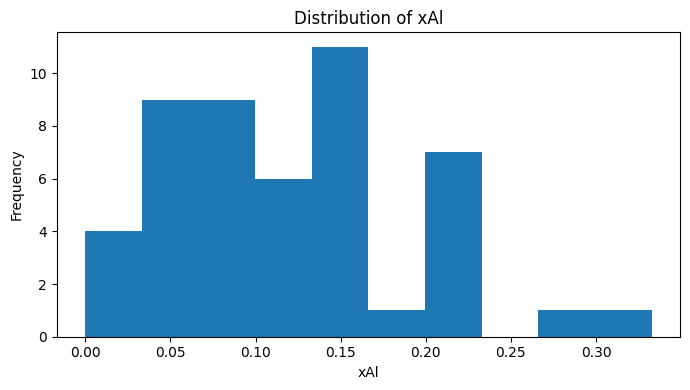

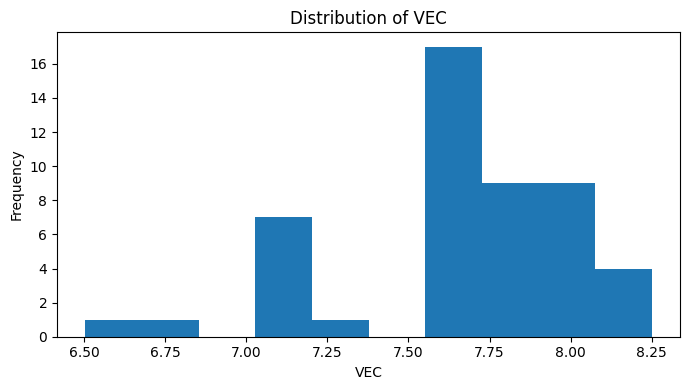

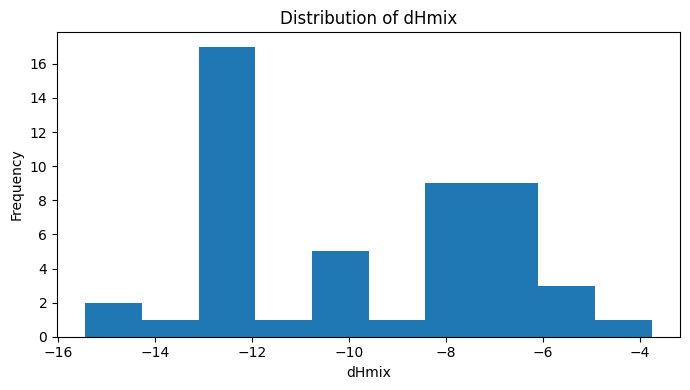

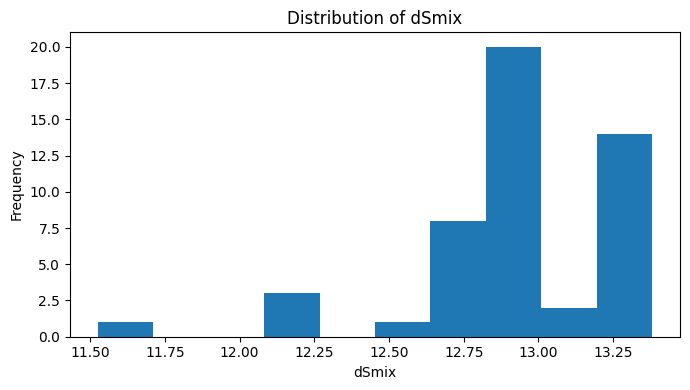

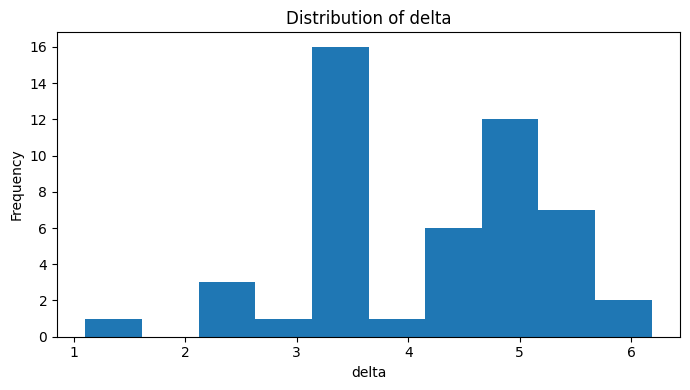

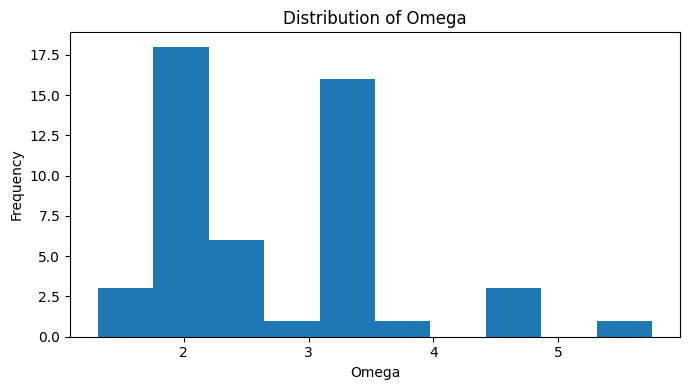

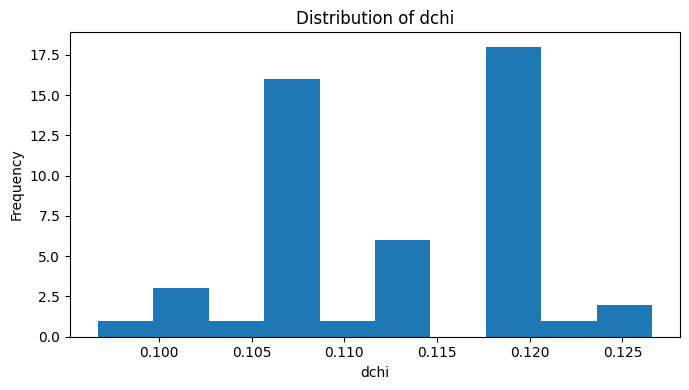

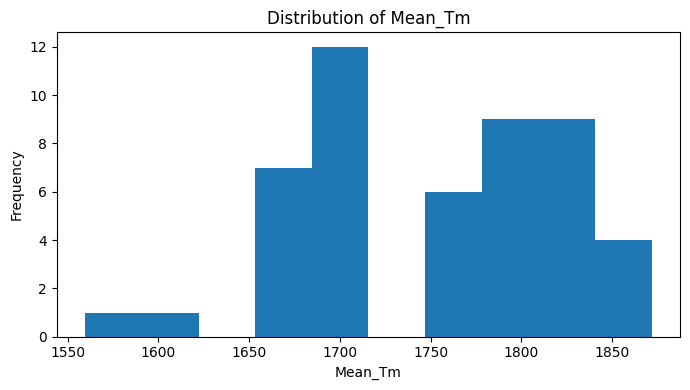

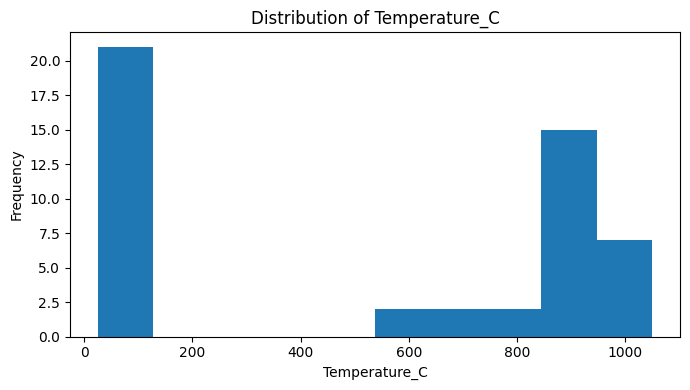

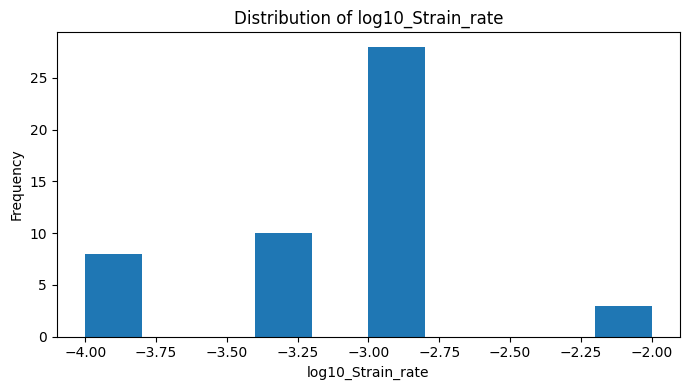

In [ ]:
for feature in FEATURES:
    plt.figure(figsize=(7, 4))

    plt.hist(df[feature], bins=10)

    plt.xlabel(feature)
    plt.ylabel("Frequency")
    plt.title(f"Distribution of {feature}")

    plt.tight_layout()
    plt.show()

# UTS distribution

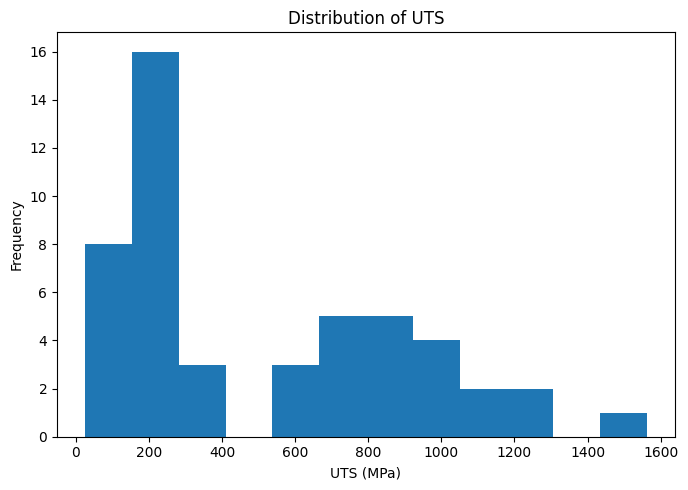

In [ ]:
plt.figure(figsize=(7, 5))

plt.hist(df[TARGET], bins=12)

plt.xlabel("UTS (MPa)")
plt.ylabel("Frequency")
plt.title("Distribution of UTS")

plt.tight_layout()
plt.show()

# Temperature distribution

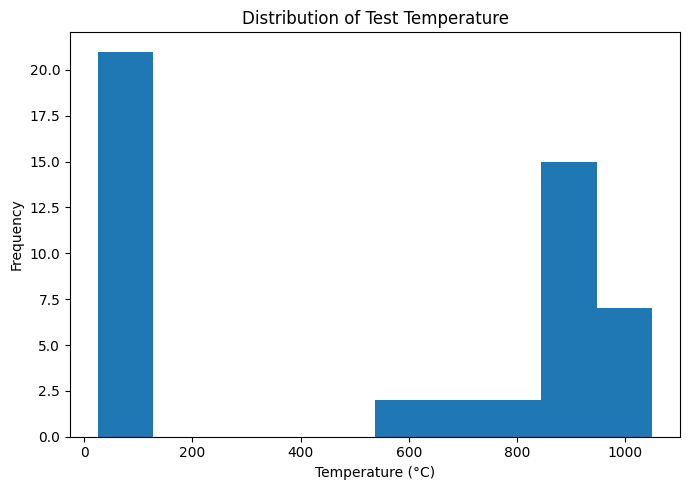

In [ ]:
plt.figure(figsize=(7, 5))

plt.hist(df["Temperature_C"], bins=10)

plt.xlabel("Temperature (°C)")
plt.ylabel("Frequency")
plt.title("Distribution of Test Temperature")

plt.tight_layout()
plt.show()

# Strain-rate distribution

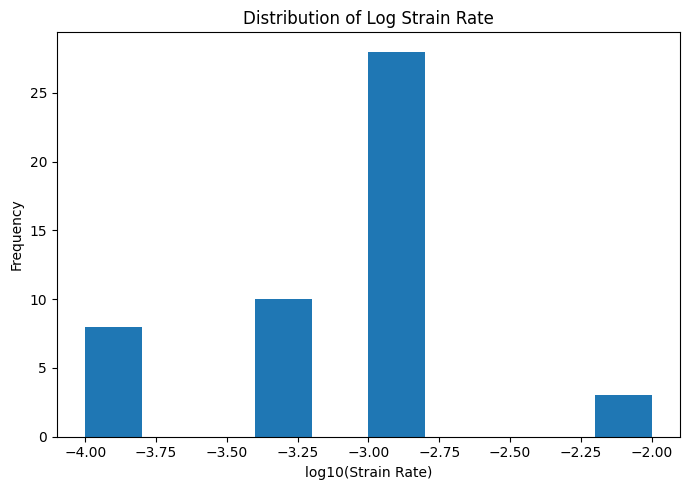

In [ ]:
plt.figure(figsize=(7, 5))

plt.hist(df["log10_Strain_rate"], bins=10)

plt.xlabel("log10(Strain Rate)")
plt.ylabel("Frequency")
plt.title("Distribution of Log Strain Rate")

plt.tight_layout()
plt.show()

# Feature–UTS correlation

In [ ]:
correlation = df[FEATURES + [TARGET]].corr()

print(correlation[TARGET].sort_values(ascending=False))

UTS_MPa              1.000000
VEC                  0.167857
Mean_Tm              0.135920
dHmix                0.109928
dSmix                0.033615
Omega                0.014905
log10_Strain_rate    0.001076
delta               -0.056895
dchi                -0.089061
xAl                 -0.149212
Temperature_C       -0.880835
Name: UTS_MPa, dtype: float64


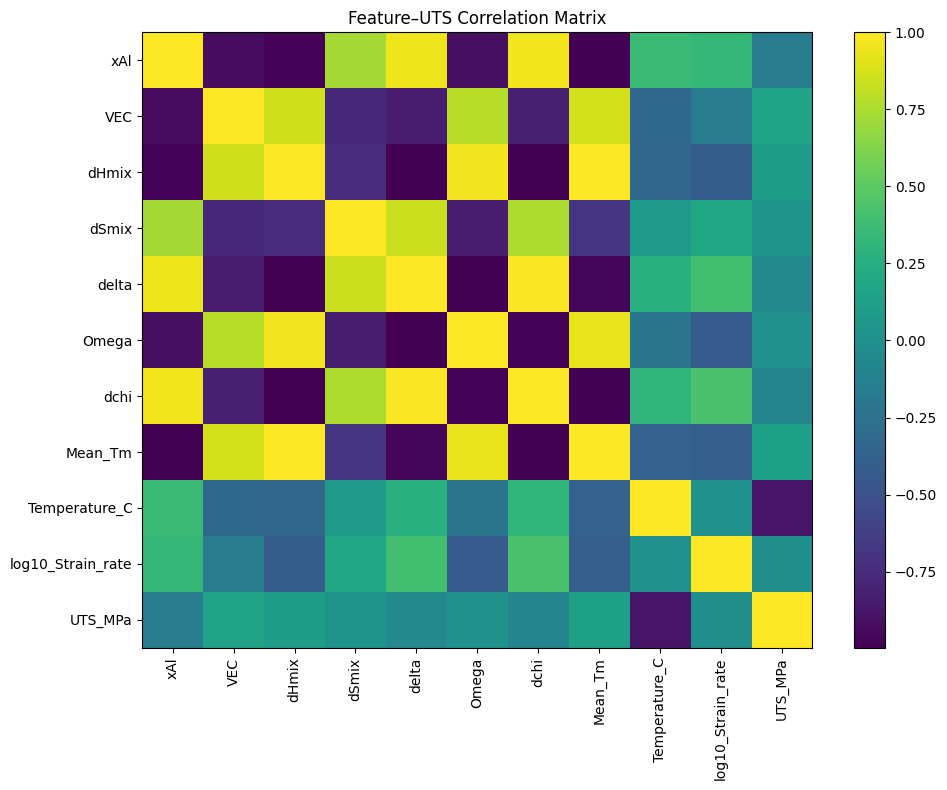

In [ ]:
plt.figure(figsize=(10, 8))

plt.imshow(
    correlation,
    aspect="auto"
)

plt.colorbar()

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Feature–UTS Correlation Matrix")

plt.tight_layout()
plt.show()

# Observation-level train/test benchmark

In [ ]:
X = df[FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_SEED
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 39
Testing samples: 10


# Random Forest Regressor Training

In [ ]:
rf_model = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "rf",
        RandomForestRegressor(
            n_estimators=300,
            random_state=RANDOM_SEED,
            n_jobs=-1
        )
    )
])

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

In [ ]:
rf_mae = mean_absolute_error(y_test, rf_pred)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_pred)
)

rf_r2 = r2_score(
    y_test,
    rf_pred
)

print("Random Forest")
print("=============")
print(f"MAE  : {rf_mae:.4f} MPa")
print(f"RMSE : {rf_rmse:.4f} MPa")
print(f"R²   : {rf_r2:.4f}")

Random Forest
MAE  : 134.9519 MPa
RMSE : 189.1418 MPa
R²   : 0.6301


# SVR Training

In [ ]:
svr_model = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "svr",
        SVR(
            kernel="rbf",
            C=100,
            epsilon=0.1,
            gamma="scale"
        )
    )
])

svr_model.fit(X_train, y_train)

svr_pred = svr_model.predict(X_test)

In [ ]:
svr_mae = mean_absolute_error(
    y_test,
    svr_pred
)

svr_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        svr_pred
    )
)

svr_r2 = r2_score(
    y_test,
    svr_pred
)

print("SVR")
print("===")
print(f"MAE  : {svr_mae:.4f} MPa")
print(f"RMSE : {svr_rmse:.4f} MPa")
print(f"R²   : {svr_r2:.4f}")

SVR
===
MAE  : 220.9534 MPa
RMSE : 250.7012 MPa
R²   : 0.3502


# Combined Results

In [ ]:
observation_results = pd.DataFrame({
    "Model": [
        "Random Forest",
        "SVR"
    ],
    "MAE": [
        rf_mae,
        svr_mae
    ],
    "RMSE": [
        rf_rmse,
        svr_rmse
    ],
    "R2": [
        rf_r2,
        svr_r2
    ]
})

display(observation_results)

,Model,MAE,RMSE,R2
0,Random Forest,134.951867,189.141846,0.630124
1,SVR,220.953435,250.701237,0.350179


# Plotting Actual Vs Predicted - Random Forest

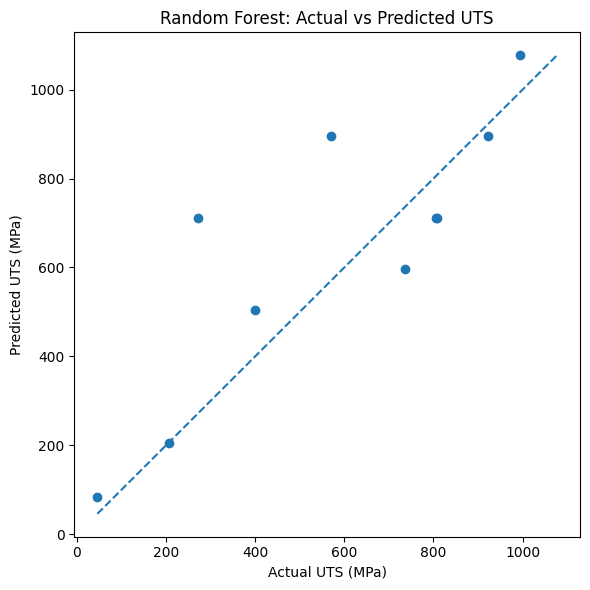

In [ ]:
plt.figure(figsize=(6, 6))

plt.scatter(
    y_test,
    rf_pred
)

min_val = min(
    y_test.min(),
    rf_pred.min()
)

max_val = max(
    y_test.max(),
    rf_pred.max()
)

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.xlabel("Actual UTS (MPa)")
plt.ylabel("Predicted UTS (MPa)")
plt.title("Random Forest: Actual vs Predicted UTS")

plt.tight_layout()
plt.show()

# Plotting Actual Vs Predicted - SVR

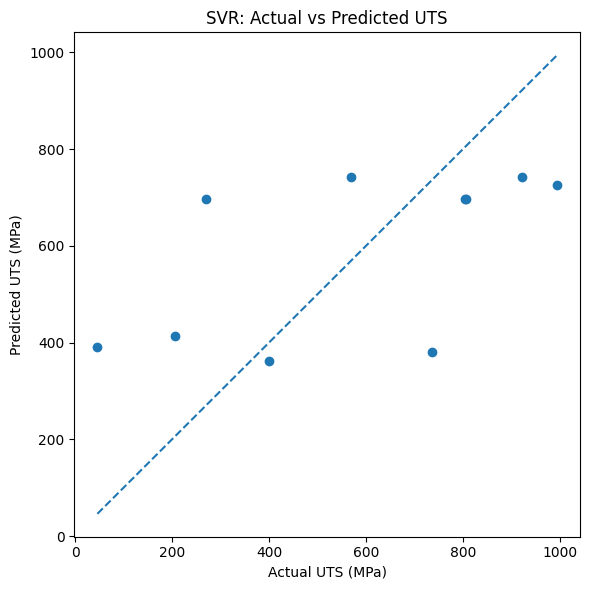

In [ ]:
plt.figure(figsize=(6, 6))

plt.scatter(
    y_test,
    svr_pred
)

min_val = min(
    y_test.min(),
    svr_pred.min()
)

max_val = max(
    y_test.max(),
    svr_pred.max()
)

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.xlabel("Actual UTS (MPa)")
plt.ylabel("Predicted UTS (MPa)")
plt.title("SVR: Actual vs Predicted UTS")

plt.tight_layout()
plt.show()

# Residual Plots

# RF Residuals

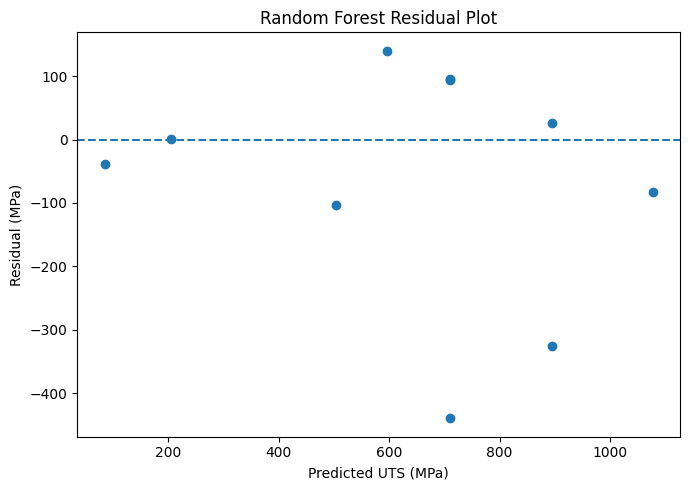

In [ ]:
rf_residuals = y_test - rf_pred

plt.figure(figsize=(7, 5))

plt.scatter(
    rf_pred,
    rf_residuals
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Predicted UTS (MPa)")
plt.ylabel("Residual (MPa)")
plt.title("Random Forest Residual Plot")

plt.tight_layout()
plt.show()

# SVR Residuals

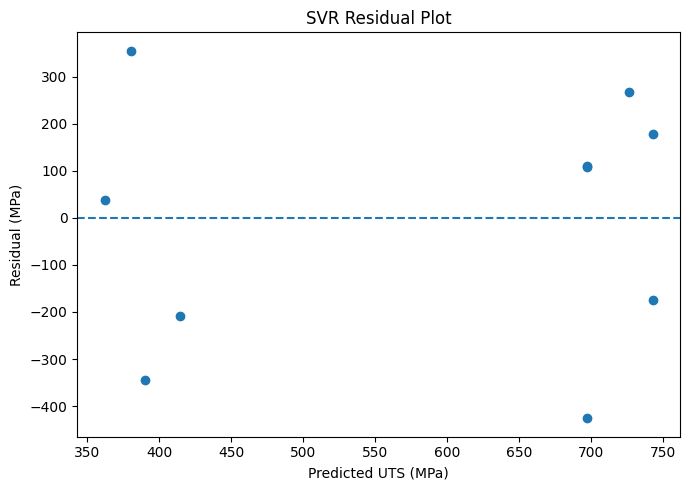

In [ ]:
svr_residuals = y_test - svr_pred

plt.figure(figsize=(7, 5))

plt.scatter(
    svr_pred,
    svr_residuals
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Predicted UTS (MPa)")
plt.ylabel("Residual (MPa)")
plt.title("SVR Residual Plot")

plt.tight_layout()
plt.show()

# Error distribution

RF

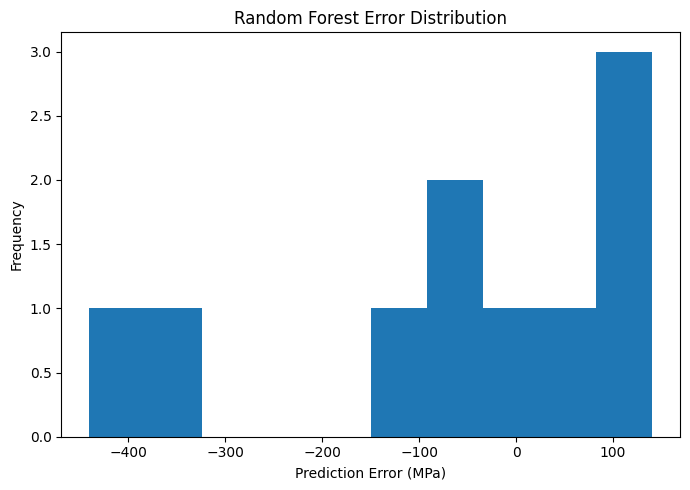

In [ ]:
plt.figure(figsize=(7, 5))

plt.hist(rf_residuals, bins=10)

plt.xlabel("Prediction Error (MPa)")
plt.ylabel("Frequency")
plt.title("Random Forest Error Distribution")

plt.tight_layout()
plt.show()

SVR

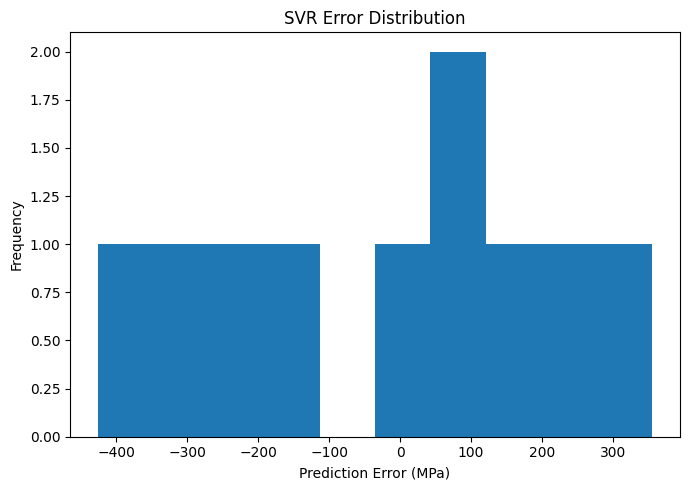

In [ ]:
plt.figure(figsize=(7, 5))

plt.hist(svr_residuals, bins=10)

plt.xlabel("Prediction Error (MPa)")
plt.ylabel("Frequency")
plt.title("SVR Error Distribution")

plt.tight_layout()
plt.show()

# Composition-Level Group K-Fold

In [ ]:
from sklearn.model_selection import GroupKFold

groups = df["Composition_Group"]

X = df[FEATURES]
y = df[TARGET]

gkf = GroupKFold(n_splits=5)

In [ ]:
from sklearn.model_selection import GroupKFold

X = df[FEATURES].copy()
y = df[TARGET].copy()
groups = df["Composition_Group"].copy()

n_repeats = 5
n_splits = 5

rf_repeat_scores = []
svr_repeat_scores = []

rf_all_predictions = []
svr_all_predictions = []

for repeat in range(n_repeats):

    print(f"\n========== REPEAT {repeat + 1} ==========")

    gkf = GroupKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=RANDOM_SEED + repeat
    )

    # Store all out-of-fold predictions for this repeat
    rf_true = []
    rf_pred_all = []

    svr_true = []
    svr_pred_all = []

    for fold, (train_idx, test_idx) in enumerate(
        gkf.split(X, y, groups),
        start=1
    ):

        X_train = X.iloc[train_idx]
        X_test = X.iloc[test_idx]

        y_train = y.iloc[train_idx]
        y_test = y.iloc[test_idx]

        # -------------------------
        # Random Forest
        # -------------------------

        rf = RandomForestRegressor(
            n_estimators=300,
            random_state=RANDOM_SEED,
            n_jobs=-1
        )

        rf.fit(X_train, y_train)

        rf_pred = rf.predict(X_test)

        rf_true.extend(y_test.tolist())
        rf_pred_all.extend(rf_pred.tolist())

        # -------------------------
        # SVR
        # -------------------------

        svr = Pipeline([
            ("scaler", StandardScaler()),
            ("svr", SVR(
                kernel="rbf",
                C=100,
                epsilon=0.1,
                gamma="scale"
            ))
        ])

        svr.fit(X_train, y_train)

        svr_pred = svr.predict(X_test)

        svr_true.extend(y_test.tolist())
        svr_pred_all.extend(svr_pred.tolist())

        print(f"Fold {fold} completed")

    # =====================================
    # Calculate metrics AFTER all 5 folds
    # =====================================

    rf_mae = mean_absolute_error(
        rf_true,
        rf_pred_all
    )

    rf_rmse = np.sqrt(
        mean_squared_error(
            rf_true,
            rf_pred_all
        )
    )

    rf_r2 = r2_score(
        rf_true,
        rf_pred_all
    )

    rf_repeat_scores.append({
        "Repeat": repeat + 1,
        "MAE": rf_mae,
        "RMSE": rf_rmse,
        "R2": rf_r2
    })

    # -------------------------------------

    svr_mae = mean_absolute_error(
        svr_true,
        svr_pred_all
    )

    svr_rmse = np.sqrt(
        mean_squared_error(
            svr_true,
            svr_pred_all
        )
    )

    svr_r2 = r2_score(
        svr_true,
        svr_pred_all
    )

    svr_repeat_scores.append({
        "Repeat": repeat + 1,
        "MAE": svr_mae,
        "RMSE": svr_rmse,
        "R2": svr_r2
    })

    print(f"Repeat {repeat + 1} completed")


========== REPEAT 1 ==========
Fold 1 completed
Fold 2 completed
Fold 3 completed
Fold 4 completed
Fold 5 completed
Repeat 1 completed

========== REPEAT 2 ==========
Fold 1 completed
Fold 2 completed
Fold 3 completed
Fold 4 completed
Fold 5 completed
Repeat 2 completed

========== REPEAT 3 ==========
Fold 1 completed
Fold 2 completed
Fold 3 completed
Fold 4 completed
Fold 5 completed
Repeat 3 completed

========== REPEAT 4 ==========
Fold 1 completed
Fold 2 completed
Fold 3 completed
Fold 4 completed
Fold 5 completed
Repeat 4 completed

========== REPEAT 5 ==========
Fold 1 completed
Fold 2 completed
Fold 3 completed
Fold 4 completed
Fold 5 completed
Repeat 5 completed


# Convert results to DataFrames

In [ ]:
rf_repeat_results = pd.DataFrame(
    rf_repeat_scores
)

svr_repeat_results = pd.DataFrame(
    svr_repeat_scores
)

print("Random Forest:")
display(rf_repeat_results)

print("SVR:")
display(svr_repeat_results)

Random Forest:


,Repeat,MAE,RMSE,R2
0,1,104.410725,178.139903,0.796653
1,2,116.581514,198.042812,0.748676
2,3,102.830129,171.154213,0.812289
3,4,104.698035,172.753320,0.808765
4,5,116.918390,198.271551,0.748096


SVR:


,Repeat,MAE,RMSE,R2
0,1,217.153335,297.963329,0.431094
1,2,217.148517,299.765711,0.424190
2,3,226.659531,300.946934,0.419643
3,4,231.974966,302.748828,0.412673
4,5,227.788912,304.830821,0.404567


# Final composition-level RF result

In [ ]:
print("======================================")
print("FINAL COMPOSITION-LEVEL RANDOM FOREST")
print("======================================")

print(
    f"MAE  : "
    f"{rf_repeat_results['MAE'].mean():.4f}"
    f" ± "
    f"{rf_repeat_results['MAE'].std():.4f}"
)

print(
    f"RMSE : "
    f"{rf_repeat_results['RMSE'].mean():.4f}"
    f" ± "
    f"{rf_repeat_results['RMSE'].std():.4f}"
)

print(
    f"R²   : "
    f"{rf_repeat_results['R2'].mean():.4f}"
    f" ± "
    f"{rf_repeat_results['R2'].std():.4f}"
)

FINAL COMPOSITION-LEVEL RANDOM FOREST
MAE  : 109.0878 ± 7.0317
RMSE : 183.6724 ± 13.4739
R²   : 0.7829 ± 0.0320


# Final composition-level SVR result

In [ ]:
print("======================================")
print("FINAL COMPOSITION-LEVEL SVR")
print("======================================")

print(
    f"MAE  : "
    f"{svr_repeat_results['MAE'].mean():.4f}"
    f" ± "
    f"{svr_repeat_results['MAE'].std():.4f}"
)

print(
    f"RMSE : "
    f"{svr_repeat_results['RMSE'].mean():.4f}"
    f" ± "
    f"{svr_repeat_results['RMSE'].std():.4f}"
)

print(
    f"R²   : "
    f"{svr_repeat_results['R2'].mean():.4f}"
    f" ± "
    f"{svr_repeat_results['R2'].std():.4f}"
)

FINAL COMPOSITION-LEVEL SVR
MAE  : 224.1451 ± 6.6847
RMSE : 301.2511 ± 2.6536
R²   : 0.4184 ± 0.0103


# Final grouped-results table

In [ ]:
final_grouped_results = pd.DataFrame({
    "Model": [
        "Random Forest",
        "SVR"
    ],

    "MAE (Mean)": [
        rf_repeat_results["MAE"].mean(),
        svr_repeat_results["MAE"].mean()
    ],

    "MAE (SD)": [
        rf_repeat_results["MAE"].std(),
        svr_repeat_results["MAE"].std()
    ],

    "RMSE (Mean)": [
        rf_repeat_results["RMSE"].mean(),
        svr_repeat_results["RMSE"].mean()
    ],

    "RMSE (SD)": [
        rf_repeat_results["RMSE"].std(),
        svr_repeat_results["RMSE"].std()
    ],

    "R2 (Mean)": [
        rf_repeat_results["R2"].mean(),
        svr_repeat_results["R2"].mean()
    ],

    "R2 (SD)": [
        rf_repeat_results["R2"].std(),
        svr_repeat_results["R2"].std()
    ]
})

display(final_grouped_results)

,Model,MAE (Mean),MAE (SD),RMSE (Mean),RMSE (SD),R2 (Mean),R2 (SD)
0,Random Forest,109.087758,7.031668,183.672360,13.473899,0.782896,0.032033
1,SVR,224.145052,6.684749,301.251125,2.653579,0.418434,0.010251


# Final Results

In [ ]:
with pd.ExcelWriter(
    "Classical_ML_Results_Final.xlsx",
    engine="openpyxl"
) as writer:

    observation_results.to_excel(
        writer,
        sheet_name="Observation_Level",
        index=False
    )

    final_grouped_results.to_excel(
        writer,
        sheet_name="Composition_Level",
        index=False
    )

    rf_repeat_results.to_excel(
        writer,
        sheet_name="RF_Repeated_Runs",
        index=False
    )

    svr_repeat_results.to_excel(
        writer,
        sheet_name="SVR_Repeated_Runs",
        index=False
    )

    composition_summary.to_excel(
        writer,
        sheet_name="Composition_Summary"
    )

print("Final results saved.")

Final results saved.
